In [1]:
import os

broken_path = "/cluster/tufts/apps/manual/9/x86_64/jupyter/4.5.0/bin"

if broken_path in os.environ.get("PATH", ""):
    os.environ["PATH"] = os.environ["PATH"].replace(broken_path + ":", "").replace(broken_path, "")

import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 10,
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],
})


In [2]:
import copy
import random
import numpy as np
import pandas as pd
import torch


In [3]:
import sys
sys.path.append("../src/")

%load_ext autoreload
%autoreload 2
# Importing our custom module(s)
import models
import layers
import utils


In [4]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)


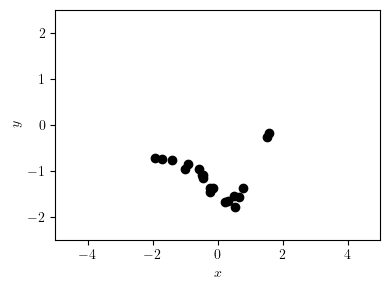

In [5]:
N = 20
D = 1
X_numpy = np.random.randn(N, D)
K = utils.rbf_kernel(X_numpy, X_numpy, lengthscale=1.0, outputscale=1.0)
#K = utils.matern_kernel(X_numpy, X_numpy, lengthscale=1.0, nu=2.5, outputscale=1.0)
#y_numpy = np.sin(3 * np.sum(X_numpy, axis=1, keepdims=True)) + 0.1 * np.random.randn(N, 1)
y_numpy = np.random.multivariate_normal(mean=np.zeros(N), cov=K, size=1).reshape(N, 1) + 0.1 * np.random.randn(N, 1)

X = torch.tensor(X_numpy.reshape(-1, 1), dtype=torch.float64)
y = torch.tensor(y_numpy.reshape(-1, 1), dtype=torch.float64)

ncols, nrows = 1, 1
fig, ax = plt.subplots(figsize=(4*ncols, 3*nrows), ncols=ncols, nrows=nrows)

ax.scatter(X_numpy, y_numpy, color="#000000")
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim([-5, 5])
ax.set_ylim([-2.5, 2.5])

fig.tight_layout()
plt.show()


In [6]:
phi_f = layers.ScaleFeatures(layers.RBFRFFs(D=D, lengthscale=1.0, R=256))
phi_g = layers.ScaleFeatures(layers.RBFRFFs(D=D, lengthscale=1.0, R=256))
init = {
    "phi_f": copy.deepcopy(phi_f.state_dict()),
    "phi_g": copy.deepcopy(phi_g.state_dict()),
}    

In [11]:
phi_f = layers.ScaleFeatures(layers.RBFRFFs(D=D, lengthscale=1.0, R=256))
phi_g = layers.ScaleFeatures(layers.RBFRFFs(D=D, lengthscale=1.0, R=256))
phi_f.load_state_dict(init["phi_f"])
phi_g.load_state_dict(init["phi_g"])

model = models.WSVHGP(
    m_g=torch.randn(256, 1, dtype=torch.float64),
    mu_0=torch.zeros(1, dtype=torch.float64),
    raw_L_g=torch.randn(256, 256, dtype=torch.float64) / 256,
)
optimizer = torch.optim.Adam([
    {"params": phi_f.parameters(), "lr": 0.01},
    {"params": phi_g.parameters(), "lr": 0.01},
    {"params": model.parameters(), "lr": 0.01},
])

for step in range(1_000):
    optimizer.zero_grad()
    Phi_f, Phi_g = phi_f(X), phi_g(X)
    loss = -model.elbo(Phi_f, Phi_g, y) / len(y)
    loss.backward()
    optimizer.step()
    if step % 100 == 0:
        print(step, loss.item())

0 2.5434719540256823
100 0.009972087161886245
200 -0.13388066762127188
300 -0.20223197304048854
400 -0.24282375455879213
500 -0.27053587884292785
600 -0.29099862285691935
700 -0.30611256081447963
800 -0.320478279040486
900 -0.3318940073947175


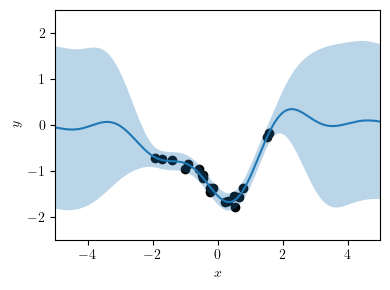

In [20]:
phi_f.eval()
phi_g.eval()

with torch.no_grad():
    Phi_f = phi_f(X)
    Phi_g = phi_g(X)
    X_star = torch.linspace(-5, 5, 500, dtype=torch.float64).unsqueeze(1)
    Phi_f_star = phi_f(X_star)
    Phi_g_star = phi_g(X_star)
    mean, var = model.predict(Phi_f_star, Phi_g_star, Phi_f, Phi_g, y)

x = X_star.squeeze().numpy()
m = mean.squeeze().numpy()
s = var.sqrt().squeeze().numpy()

fig, ax = plt.subplots(figsize=(4, 3))

ax.scatter(X_numpy, y_numpy, color="#000000")
ax.plot(x, m)
ax.fill_between(x, m - 2 * s, m + 2 * s, alpha=0.3)

ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_xlim([-5, 5])
ax.set_ylim([-2.5, 2.5])

fig.tight_layout()
plt.show()